
# Hub de Modelagem Estocástica: Cadeias de Markov e Teoria de Filas

Este notebook reúne 5 cenários clássicos de processos estocásticos, cada um com:
- a formulação do modelo (estados, transições/taxas),
- uma simulação,
- comparação com o resultado teórico (quando disponível).

**Cenários:**
1. Urna de Ehrenfest (troca de bolas entre duas caixas)
2. Ruína do apostador (gambler's ruin)
3. Fila M/M/1
4. Fila M/M/2
5. Fila M/G/1


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import comb, factorial

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True



## 1. Urna de Ehrenfest (troca de bolas entre duas caixas)

Há $N=20$ bolas em cada uma de 2 caixas (A e B), sendo brancas e vermelhas, $20$ de cada cor no total.
O estado do sistema é $X_t = $ número de bolas brancas na caixa A no instante $t$.

A cada passo, escolhe-se **uma bola ao acaso de cada caixa** e as duas trocam de caixa. Isso é equivalente
ao modelo clássico de Ehrenfest (com $2N=40$ bolas totais e $N=20$ em cada urna), mas aqui cada urna
sempre mantém exatamente 20 bolas (uma sai, uma entra).

Se a caixa A tem $i$ bolas brancas (e $20-i$ vermelhas) e a caixa B tem $20-i$ bolas brancas (e $i$ vermelhas):

- $P(\text{bola branca sai de A}) = i/20$, $P(\text{bola branca sai de B}) = (20-i)/20$.
- O número de brancas em A muda de $+1$ se sair vermelha de A e branca de B; muda de $-1$ se sair branca de A
  e vermelha de B; fica igual nos outros dois casos.

$$
P(i \to i+1) = \frac{20-i}{20}\cdot\frac{20-i}{20}, \qquad
P(i \to i-1) = \frac{i}{20}\cdot\frac{i}{20}, \qquad
P(i \to i) = 1 - P(i\to i+1) - P(i\to i-1)
$$

A distribuição estacionária é Hipergeométrica/Binomial$(20, 1/2)$: o processo tende a equilibrar as cores
entre as caixas.


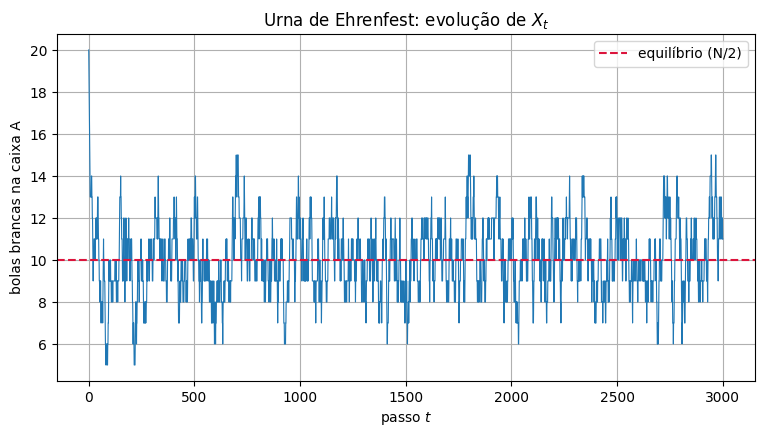

In [2]:

N = 20          # bolas em cada caixa
T1 = 3000       # passos de simulação
i0 = 20         # estado inicial: todas as 20 brancas na caixa A

def ehrenfest_step(i, N, rng):
    out_A_white = rng.random() < i / N        # sai branca de A?
    out_B_white = rng.random() < (N - i) / N   # sai branca de B?
    if out_A_white and not out_B_white:
        return i - 1
    if (not out_A_white) and out_B_white:
        return i + 1
    return i

path = np.empty(T1 + 1, dtype=int)
path[0] = i0
for t in range(T1):
    path[t + 1] = ehrenfest_step(path[t], N, rng)

fig, ax = plt.subplots()
ax.plot(path, lw=0.8)
ax.axhline(N / 2, color="crimson", ls="--", label="equilíbrio (N/2)")
ax.set_xlabel("passo $t$")
ax.set_ylabel("bolas brancas na caixa A")
ax.set_title("Urna de Ehrenfest: evolução de $X_t$")
ax.legend()
plt.show()


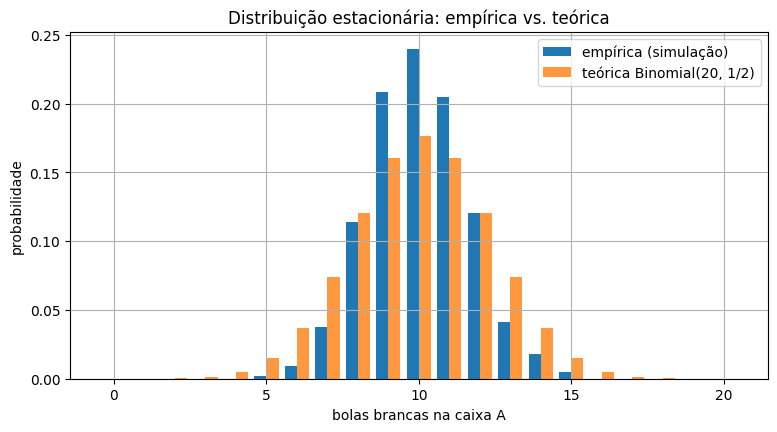

In [3]:

# Distribuição empírica (após descartar transiente) vs. Binomial(20, 1/2) teórica
burn_in = 200
emp_counts = np.bincount(path[burn_in:], minlength=N + 1)
emp_dist = emp_counts / emp_counts.sum()

states = np.arange(N + 1)
theo_dist = stats.binom(N, 0.5).pmf(states)

fig, ax = plt.subplots()
width = 0.4
ax.bar(states - width/2, emp_dist, width=width, label="empírica (simulação)")
ax.bar(states + width/2, theo_dist, width=width, label="teórica Binomial(20, 1/2)", alpha=0.8)
ax.set_xlabel("bolas brancas na caixa A")
ax.set_ylabel("probabilidade")
ax.set_title("Distribuição estacionária: empírica vs. teórica")
ax.legend()
plt.show()



## 2. Ruína do apostador (gambler's ruin)

Um apostador começa com capital $X_0$ e, a cada rodada, aposta uma quantia fixa: com probabilidade $p$
dobra a aposta (ganha o valor apostado) e com probabilidade $1-p$ perde o valor apostado. O jogo termina
quando o capital chega a 0 (ruína) ou atinge um teto $M$ (meta), o que ocorrer primeiro.

Para $p \neq 1/2$, a probabilidade de ruína partindo de $i$ é

$$
P(\text{ruína} \mid X_0 = i) = \frac{(q/p)^M - (q/p)^i}{(q/p)^M - 1}, \qquad q = 1-p
$$

e para $p = 1/2$, $P(\text{ruína}\mid X_0=i) = 1 - i/M$ (passeio aleatório simétrico).


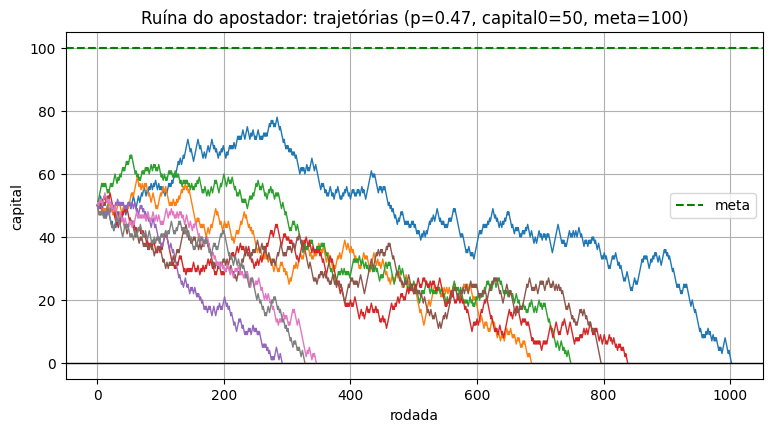

In [4]:

def simulate_gambler(capital0, M, p, bet, rng, max_steps=200_000):
    capital = capital0
    history = [capital]
    steps = 0
    while 0 < capital < M and steps < max_steps:
        capital += bet if rng.random() < p else -bet
        history.append(capital)
        steps += 1
    return np.array(history)

p = 0.47          # probabilidade de vitória (casa com vantagem)
bet = 1
capital0 = 50
M = 100            # meta / teto de capital

n_paths = 8
fig, ax = plt.subplots()
for _ in range(n_paths):
    h = simulate_gambler(capital0, M, p, bet, rng)
    ax.plot(h, lw=1)
ax.axhline(0, color="black", lw=1)
ax.axhline(M, color="green", ls="--", label="meta")
ax.set_xlabel("rodada")
ax.set_ylabel("capital")
ax.set_title(f"Ruína do apostador: trajetórias (p={p}, capital0={capital0}, meta={M})")
ax.legend()
plt.show()


P(ruína) empírica = 0.9969
P(ruína) teórica  = 0.9975


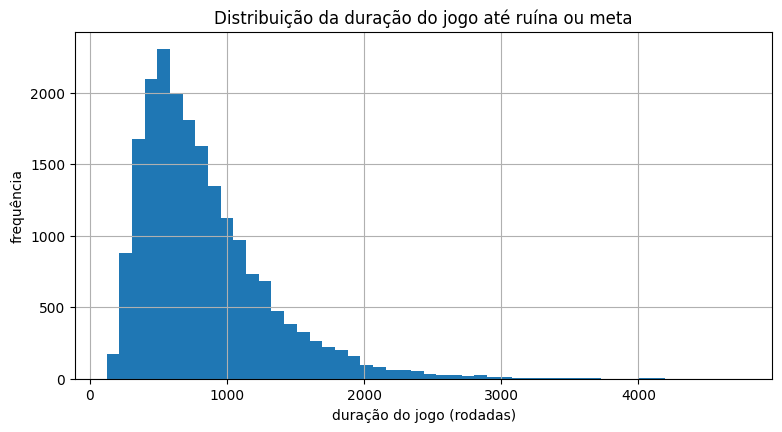

In [5]:

# Monte Carlo: probabilidade de ruína e comparação com a fórmula teórica
n_sims = 20_000
ruins = 0
lengths = []
for _ in range(n_sims):
    h = simulate_gambler(capital0, M, p, bet, rng)
    lengths.append(len(h) - 1)
    if h[-1] <= 0:
        ruins += 1

p_ruin_emp = ruins / n_sims

q = 1 - p
if p != 0.5:
    p_ruin_theo = ((q / p) ** M - (q / p) ** capital0) / ((q / p) ** M - 1)
else:
    p_ruin_theo = 1 - capital0 / M

print(f"P(ruína) empírica = {p_ruin_emp:.4f}")
print(f"P(ruína) teórica  = {p_ruin_theo:.4f}")

fig, ax = plt.subplots()
ax.hist(lengths, bins=50)
ax.set_xlabel("duração do jogo (rodadas)")
ax.set_ylabel("frequência")
ax.set_title("Distribuição da duração do jogo até ruína ou meta")
plt.show()



## 3. Fila M/M/1

Chegadas segundo processo de Poisson de taxa $\lambda$, um único servidor com tempo de serviço
exponencial de taxa $\mu$. $\rho=\lambda/\mu<1$ para estabilidade.

Distribuição estacionária do número de clientes no sistema:
$$
\pi_n = (1-\rho)\,\rho^n, \qquad n=0,1,2,\dots
$$
Número médio de clientes no sistema: $L = \dfrac{\rho}{1-\rho}$.

Simulação por eventos discretos: mantemos o relógio do próximo evento (chegada ou término de serviço).


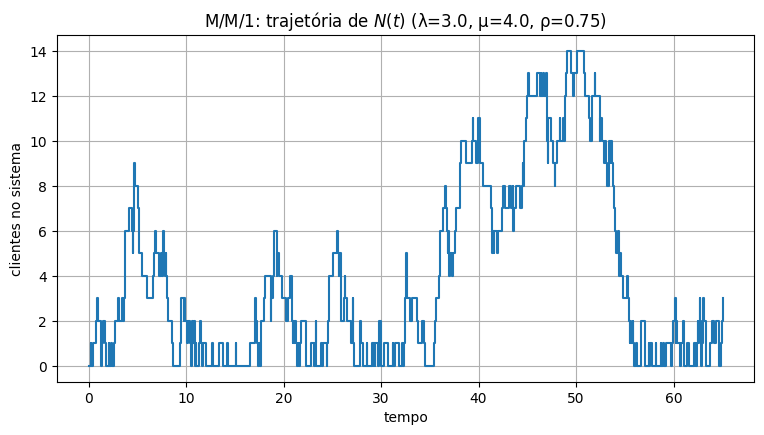

In [6]:

def simulate_mm1(lam, mu, T_end, rng):
    t = 0.0
    n_system = 0
    # próxima chegada e próxima partida (inf se não há serviço em curso)
    next_arrival = rng.exponential(1 / lam)
    next_departure = np.inf

    times = [0.0]
    levels = [0]

    while t < T_end:
        t_next = min(next_arrival, next_departure)
        if t_next > T_end:
            break
        t = t_next
        if next_arrival <= next_departure:
            n_system += 1
            next_arrival = t + rng.exponential(1 / lam)
            if n_system == 1:
                next_departure = t + rng.exponential(1 / mu)
        else:
            n_system -= 1
            next_departure = t + rng.exponential(1 / mu) if n_system > 0 else np.inf
        times.append(t)
        levels.append(n_system)
    return np.array(times), np.array(levels)

lam, mu = 3.0, 4.0     # rho = 0.75
rho = lam / mu
T_end = 2000.0

times, levels = simulate_mm1(lam, mu, T_end, rng)

fig, ax = plt.subplots()
ax.step(times[:400], levels[:400], where="post")
ax.set_xlabel("tempo")
ax.set_ylabel("clientes no sistema")
ax.set_title(f"M/M/1: trajetória de $N(t)$ (λ={lam}, μ={mu}, ρ={rho:.2f})")
plt.show()


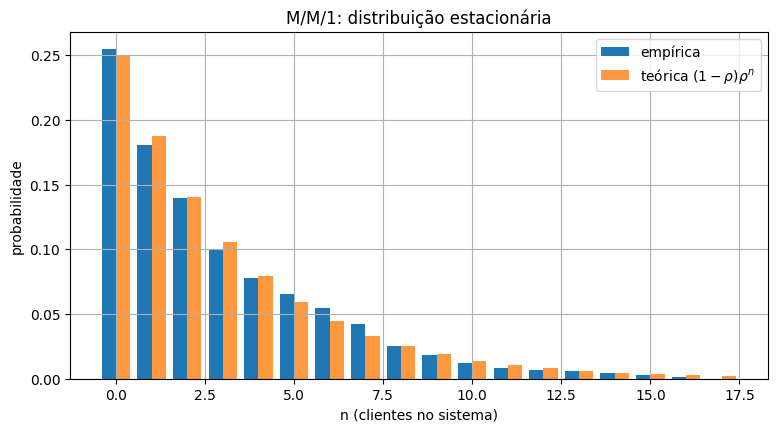

L empírico = 2.877,  L teórico = 3.000


In [7]:

# Distribuição estacionária empírica (média ponderada pelo tempo) vs. teórica
durations = np.diff(times)
state_time = np.zeros(levels[:-1].max() + 1)
for lvl, dt in zip(levels[:-1], durations):
    state_time[lvl] += dt
emp_pi = state_time / state_time.sum()

n_max = len(emp_pi)
ns = np.arange(n_max)
theo_pi = (1 - rho) * rho ** ns

fig, ax = plt.subplots()
width = 0.4
ax.bar(ns - width/2, emp_pi, width=width, label="empírica")
ax.bar(ns + width/2, theo_pi, width=width, label="teórica $(1-\\rho)\\rho^n$", alpha=0.8)
ax.set_xlabel("n (clientes no sistema)")
ax.set_ylabel("probabilidade")
ax.set_title("M/M/1: distribuição estacionária")
ax.legend()
plt.show()

L_emp = np.sum(ns * emp_pi)
L_theo = rho / (1 - rho)
print(f"L empírico = {L_emp:.3f},  L teórico = {L_theo:.3f}")



## 4. Fila M/M/2

Igual à M/M/1, mas com **2 servidores** idênticos (taxa $\mu$ cada), atendendo em paralelo. Define-se
$\rho = \lambda/(2\mu)$ para estabilidade ($\rho<1$).

Distribuição estacionária:
$$
\pi_0 = \left[1 + 2\rho + \frac{(2\rho)^2}{2(1-\rho)}\right]^{-1}, \qquad
\pi_n = \begin{cases}
\pi_0 \dfrac{(2\rho)^n}{n!}, & n \le 2 \\[4pt]
\pi_0 \dfrac{2^2 \rho^n}{2}, & n > 2
\end{cases}
$$
(aqui usando $a=\lambda/\mu$; fórmula padrão de M/M/c com $c=2$).


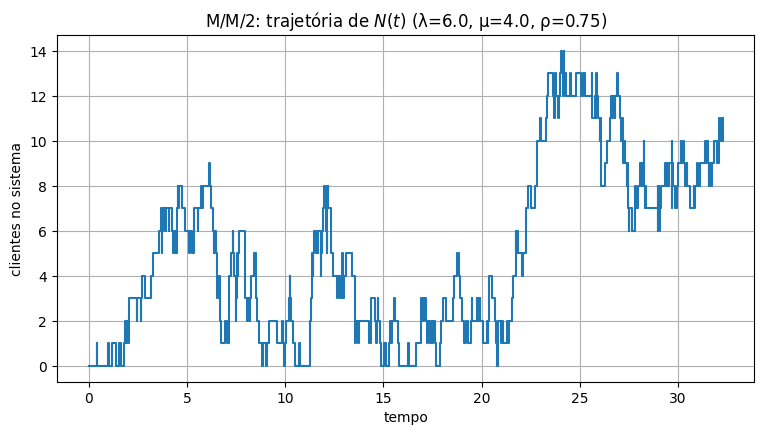

In [8]:

def simulate_mmc(lam, mu, c, T_end, rng):
    t = 0.0
    n_system = 0
    next_arrival = rng.exponential(1 / lam)
    departures = []   # próximos términos de serviço em curso (lista de tempos)

    times = [0.0]
    levels = [0]

    while t < T_end:
        next_departure = min(departures) if departures else np.inf
        t_next = min(next_arrival, next_departure)
        if t_next > T_end:
            break
        t = t_next
        if next_arrival <= next_departure:
            n_system += 1
            next_arrival = t + rng.exponential(1 / lam)
            if len(departures) < c:
                departures.append(t + rng.exponential(1 / mu))
        else:
            departures.remove(next_departure)
            n_system -= 1
            if n_system >= c:
                departures.append(t + rng.exponential(1 / mu))
        times.append(t)
        levels.append(n_system)
    return np.array(times), np.array(levels)

lam2, mu2, c = 6.0, 4.0, 2     # rho = lam/(c*mu) = 0.75
rho2 = lam2 / (c * mu2)
times2, levels2 = simulate_mmc(lam2, mu2, c, T_end, rng)

fig, ax = plt.subplots()
ax.step(times2[:400], levels2[:400], where="post")
ax.set_xlabel("tempo")
ax.set_ylabel("clientes no sistema")
ax.set_title(f"M/M/2: trajetória de $N(t)$ (λ={lam2}, μ={mu2}, ρ={rho2:.2f})")
plt.show()


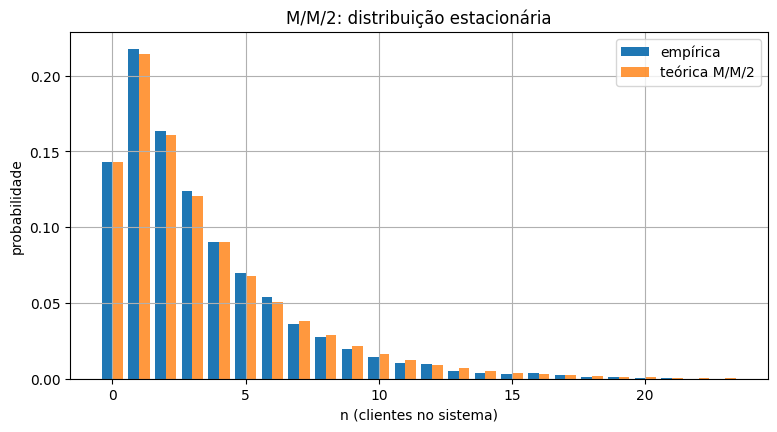

L empírico = 3.293,  L teórico = 3.429


In [9]:

durations2 = np.diff(times2)
state_time2 = np.zeros(levels2[:-1].max() + 1)
for lvl, dt in zip(levels2[:-1], durations2):
    state_time2[lvl] += dt
emp_pi2 = state_time2 / state_time2.sum()

a = lam2 / mu2   # a = c*rho
n_max2 = len(emp_pi2)
ns2 = np.arange(n_max2)

pi0 = 1.0 / (sum(a**k / factorial(k) for k in range(c)) + (a**c) / (factorial(c) * (1 - rho2)))
theo_pi2 = np.empty(n_max2)
for n in ns2:
    if n < c:
        theo_pi2[n] = pi0 * a**n / factorial(n)
    else:
        theo_pi2[n] = pi0 * a**n / (factorial(c) * c**(n - c))

fig, ax = plt.subplots()
width = 0.4
ax.bar(ns2 - width/2, emp_pi2, width=width, label="empírica")
ax.bar(ns2 + width/2, theo_pi2, width=width, label="teórica M/M/2", alpha=0.8)
ax.set_xlabel("n (clientes no sistema)")
ax.set_ylabel("probabilidade")
ax.set_title("M/M/2: distribuição estacionária")
ax.legend()
plt.show()

L_emp2 = np.sum(ns2 * emp_pi2)
Lq_theo = pi0 * a**c * rho2 / (factorial(c) * (1 - rho2)**2)
L_theo2 = Lq_theo + a
print(f"L empírico = {L_emp2:.3f},  L teórico = {L_theo2:.3f}")



## 5. Fila M/G/1

Chegadas Poisson de taxa $\lambda$, um servidor, mas o tempo de serviço $S$ segue uma distribuição
**geral** (aqui, Uniforme$(a,b)$) com média $E[S]$ e segundo momento $E[S^2]$. $\rho = \lambda E[S] < 1$.

A fórmula de **Pollaczek–Khinchine** dá o número médio de clientes no sistema:
$$
L = \rho + \frac{\lambda^2 E[S^2]}{2(1-\rho)}
$$


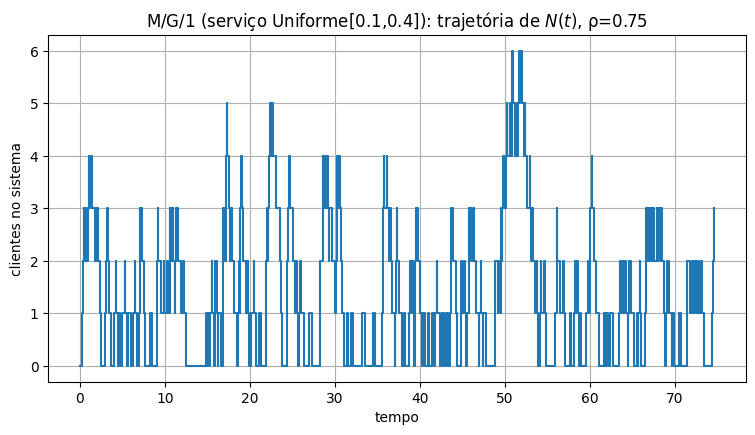

In [10]:

def simulate_mg1(lam, service_sampler, T_end, rng):
    t = 0.0
    n_system = 0
    next_arrival = rng.exponential(1 / lam)
    next_departure = np.inf

    times = [0.0]
    levels = [0]

    while t < T_end:
        t_next = min(next_arrival, next_departure)
        if t_next > T_end:
            break
        t = t_next
        if next_arrival <= next_departure:
            n_system += 1
            next_arrival = t + rng.exponential(1 / lam)
            if n_system == 1:
                next_departure = t + service_sampler(rng)
        else:
            n_system -= 1
            next_departure = t + service_sampler(rng) if n_system > 0 else np.inf
        times.append(t)
        levels.append(n_system)
    return np.array(times), np.array(levels)

# Serviço Uniforme(a, b)
a_unif, b_unif = 0.1, 0.4          # E[S] = 0.25, Var = (b-a)^2/12
lam3 = 3.0
ES = (a_unif + b_unif) / 2
ES2 = ES**2 + (b_unif - a_unif)**2 / 12
rho3 = lam3 * ES

service_sampler = lambda rng: rng.uniform(a_unif, b_unif)
times3, levels3 = simulate_mg1(lam3, service_sampler, T_end, rng)

fig, ax = plt.subplots()
ax.step(times3[:400], levels3[:400], where="post")
ax.set_xlabel("tempo")
ax.set_ylabel("clientes no sistema")
ax.set_title(f"M/G/1 (serviço Uniforme[{a_unif},{b_unif}]): trajetória de $N(t)$, ρ={rho3:.2f}")
plt.show()


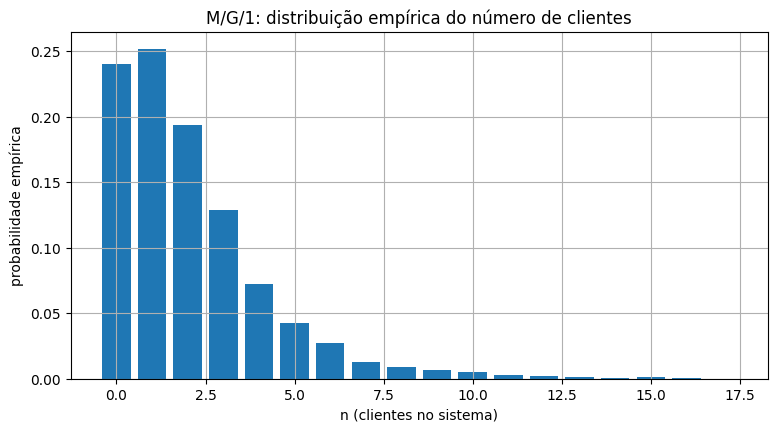

L empírico (M/G/1) = 2.076
L teórico Pollaczek-Khinchine = 2.010


In [11]:

durations3 = np.diff(times3)
state_time3 = np.zeros(levels3[:-1].max() + 1)
for lvl, dt in zip(levels3[:-1], durations3):
    state_time3[lvl] += dt
emp_pi3 = state_time3 / state_time3.sum()

ns3 = np.arange(len(emp_pi3))
L_emp3 = np.sum(ns3 * emp_pi3)
L_theo3 = rho3 + lam3**2 * ES2 / (2 * (1 - rho3))

fig, ax = plt.subplots()
ax.bar(ns3, emp_pi3)
ax.set_xlabel("n (clientes no sistema)")
ax.set_ylabel("probabilidade empírica")
ax.set_title("M/G/1: distribuição empírica do número de clientes")
plt.show()

print(f"L empírico (M/G/1) = {L_emp3:.3f}")
print(f"L teórico Pollaczek-Khinchine = {L_theo3:.3f}")
